Accuracy: 0.8625
Confusion Matrix:
 [[1536   57]
 [ 218  189]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.77      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000



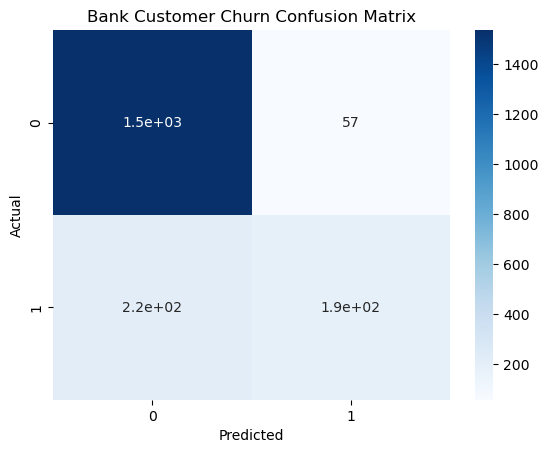

In [12]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read dataset
df = pd.read_csv('churn_modelling.csv')

# Drop unnecessary columns
df.drop(['RowNumber', 'CustomerId', 'Surname'],
        axis=1, inplace=True)

# Encode categorical columns
df = pd.get_dummies(
    df,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

# Separate features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# Split dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardisation
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build neural network
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    learning_rate='adaptive',
    max_iter=1000,
    early_stopping=True,
    random_state=42
)

# Train model
model.fit(X_train_scaled, y_train)

# Predict
y_pred = model.predict(X_test_scaled)

# Evaluate
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

print("Classification Report:\n",
      classification_report(y_test, y_pred))

# Plot confusion matrix
sns.heatmap(cm, annot=True, cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Bank Customer Churn Confusion Matrix')
plt.show()


In [10]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Read dataset
df = pd.read_csv('churn_modelling.csv')

# 2. Remove unnecessary columns
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True)

# 3. Remove outliers using IQR method
def remove_outliers(df, feature):
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[feature] >= lower_bound) &
            (df[feature] <= upper_bound)]

    return df

# Remove outliers
df = remove_outliers(df, 'Age')
df = remove_outliers(df, 'CreditScore')

print("Shape after removing outliers:", df.shape)

# 4. Encode categorical columns
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

# 5. Separate features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Normalize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8. Build ANN model
model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

# 9. Train model
model.fit(X_train_scaled, y_train)

# 10. Predict
y_pred = model.predict(X_test_scaled)

# 11. Evaluate model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred))

Shape after removing outliers: (9627, 11)
Accuracy: 0.8566978193146417
Confusion Matrix:
[[1476   60]
 [ 216  174]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1536
           1       0.74      0.45      0.56       390

    accuracy                           0.86      1926
   macro avg       0.81      0.70      0.74      1926
weighted avg       0.85      0.86      0.84      1926

